Device: cuda
Using Colab cache for faster access to the 'ai-resume-screening-dataset-30k-records' dataset.
Using dataset: /kaggle/input/ai-resume-screening-dataset-30k-records/ai_resume_screening.csv
Original dataset shape: (30000, 7)
Cleaned dataset shape: (30000, 7)

Job-level distribution:
job_role
Mid Level       16556
Senior Level    12506
Entry Level       938
Name: count, dtype: int64

Training records: 24000
Testing records: 6000
Unique training states: 2671
Q-Learning done | Macro F1 = 0.9269 | unseen test states: 160
SARSA done      | Macro F1 = 0.9082 | unseen test states: 160
DQN input features: 9
DQN episode 1000/5000 | reward/step: -0.0295
DQN episode 2000/5000 | reward/step: 0.2705
DQN episode 3000/5000 | reward/step: 0.5985
DQN episode 4000/5000 | reward/step: 0.9065
DQN episode 5000/5000 | reward/step: 0.9290
DQN done        | Macro F1 = 0.9923

FINAL PERFORMANCE COMPARISON


,Algorithm,Accuracy,Macro Precision,Macro Recall,Macro F1,Entry F1,Mean Test Reward
0,Q-Learning,0.9697,0.8925,0.9761,0.9269,0.8304,0.9393
1,SARSA,0.9643,0.8675,0.9746,0.9082,0.7792,0.9287
2,DQN,0.9970,0.9868,0.9979,0.9923,0.9817,0.9940


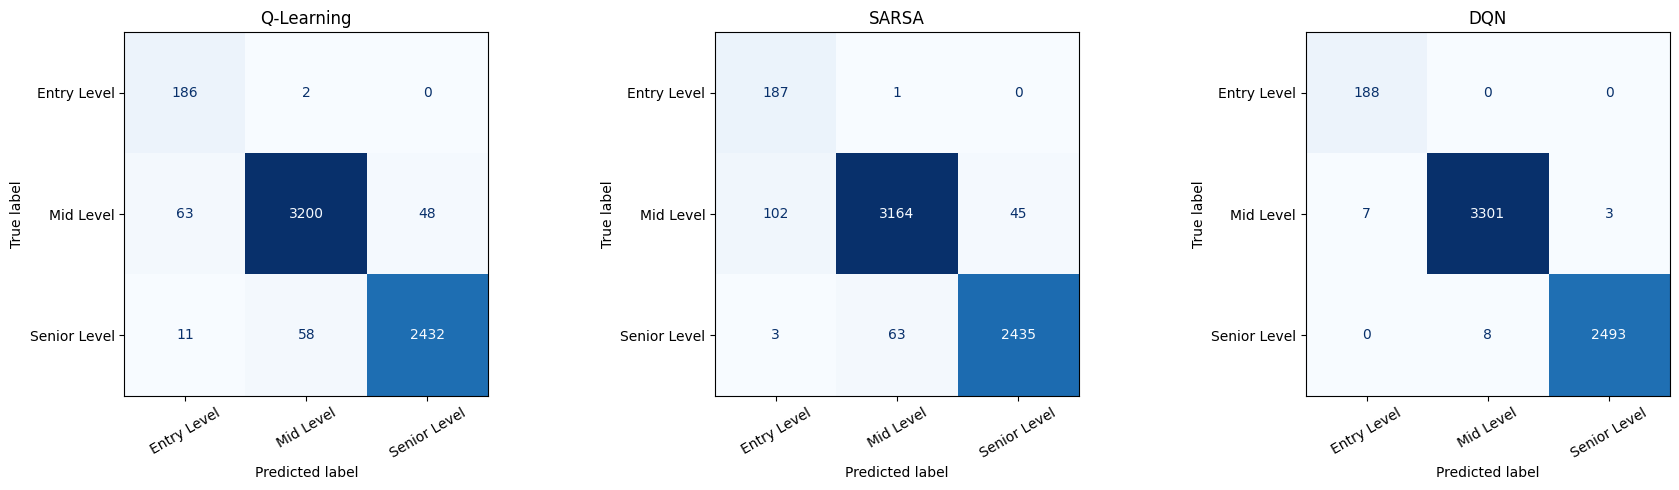


Q-Learning
              precision    recall  f1-score   support

 Entry Level     0.7154    0.9894    0.8304       188
   Mid Level     0.9816    0.9665    0.9740      3311
Senior Level     0.9806    0.9724    0.9765      2501

    accuracy                         0.9697      6000
   macro avg     0.8925    0.9761    0.9269      6000
weighted avg     0.9729    0.9697    0.9705      6000


SARSA
              precision    recall  f1-score   support

 Entry Level     0.6404    0.9947    0.7792       188
   Mid Level     0.9802    0.9556    0.9677      3311
Senior Level     0.9819    0.9736    0.9777      2501

    accuracy                         0.9643      6000
   macro avg     0.8675    0.9746    0.9082      6000
weighted avg     0.9702    0.9643    0.9660      6000


DQN
              precision    recall  f1-score   support

 Entry Level     0.9641    1.0000    0.9817       188
   Mid Level     0.9976    0.9970    0.9973      3311
Senior Level     0.9988    0.9968    0.9978      25

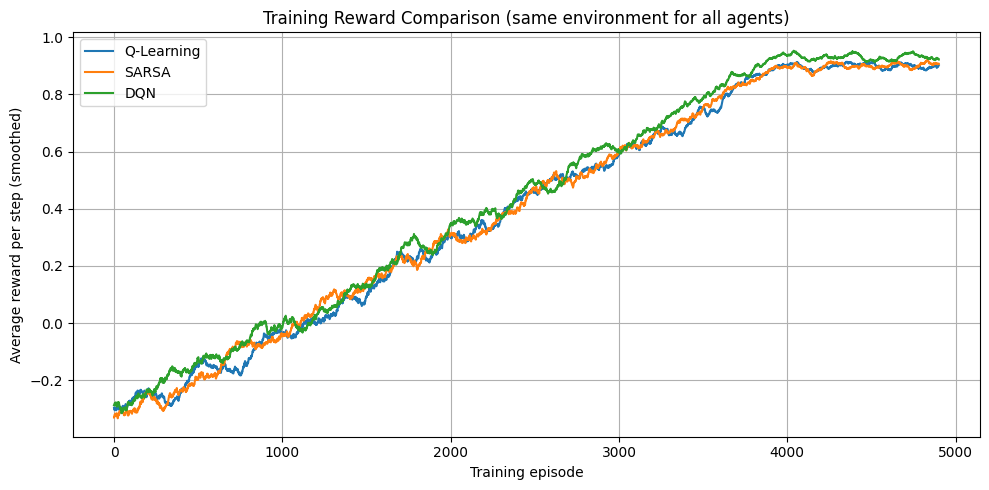


All three models have completed evaluation.
Note: job-level labels and rewards are simulated from predefined rules.


In [2]:
# ================================================================
# REINFORCEMENT LEARNING FOR JOB RECOMMENDATION
# Q-Learning vs SARSA vs DQN  (FAIR COMPARISON)
# Dataset: AI Resume Screening Dataset (30K Records)
#
# All three agents use the SAME environment, SAME episodes, SAME reward,
# SAME exploration schedule, SAME gamma and SAME class-balanced sampling.
# ================================================================

!pip -q install kagglehub

import os
import glob
import random
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer, LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

import torch
import torch.nn as nn
import torch.optim as optim

# -------------------- 1. CONFIGURATION ----------------------------

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

N_ACTIONS = 3
GAMMA = 0.5          # > 0, so Q-Learning and SARSA genuinely differ
ALPHA = 0.1          # tabular learning rate
EP_LEN = 20          # candidates shown per episode
EPISODES = 5000      # SAME for all three agents
EPS_START = 1.0
EPS_END = 0.05
KEY_BINS = 12        # bins for years_experience and skills_match_score
OTHER_BINS = 2       # bins for the remaining numeric features
F1_TARGET = 0.75

def epsilon_at(ep):
    """Same exploration schedule for every agent."""
    return max(EPS_END,
               EPS_START - (EPS_START - EPS_END) * ep / (0.8 * EPISODES))

# -------------------- 2. DOWNLOAD DATASET -------------------------

path = kagglehub.dataset_download(
    "ranaghulamnabi/ai-resume-screening-dataset-30k-records"
)

csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

required_columns = {
    "years_experience", "skills_match_score", "education_level",
    "project_count", "resume_length", "github_activity"
}

df = None

for file in csv_files:
    temp = pd.read_csv(file)
    temp.columns = temp.columns.str.strip().str.lower()

    if required_columns.issubset(set(temp.columns)):
        df = temp.copy()
        print("Using dataset:", file)
        break

if df is None:
    raise ValueError("Could not find a CSV containing the required columns.")

print("Original dataset shape:", df.shape)

# -------------------- 3. DATA CLEANING ----------------------------

numeric_columns = [
    "years_experience", "skills_match_score", "project_count",
    "resume_length", "github_activity"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["education_level"] = (
    df["education_level"].fillna("Unknown").astype(str).str.strip()
)

df = df.dropna(subset=numeric_columns).copy()

print("Cleaned dataset shape:", df.shape)

# -------------------- 4. CREATE JOB-LEVEL LABELS ------------------

def assign_job_role(row):
    exp = row["years_experience"]
    skills = row["skills_match_score"]

    if exp < 2 and skills < 50:
        return "Entry Level"
    elif exp >= 5 and skills >= 75:
        return "Senior Level"
    else:
        return "Mid Level"

df["job_role"] = df.apply(assign_job_role, axis=1)

label_map = {"Entry Level": 0, "Mid Level": 1, "Senior Level": 2}
df["target"] = df["job_role"].map(label_map).astype(int)

print("\nJob-level distribution:")
print(df["job_role"].value_counts())

# -------------------- 5. TRAIN-TEST SPLIT -------------------------

feature_columns = [
    "years_experience", "skills_match_score", "education_level",
    "project_count", "resume_length", "github_activity"
]

X = df[feature_columns].copy()
y = df["target"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

y_train = np.asarray(y_train, dtype=int)
y_test = np.asarray(y_test, dtype=int)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# -------------------- 6. CREATE TABULAR STATES --------------------
# Finer bins for the two features that matter most, coarse for the rest.

key_features = ["years_experience", "skills_match_score"]
other_features = ["project_count", "resume_length", "github_activity"]

disc_key = KBinsDiscretizer(
    n_bins=KEY_BINS, encode="ordinal", strategy="quantile", subsample=None
)
disc_other = KBinsDiscretizer(
    n_bins=OTHER_BINS, encode="ordinal", strategy="quantile", subsample=None
)

education_encoder = LabelEncoder()
education_encoder.fit(df["education_level"].astype(str))

def make_states(X_part, fit=False):
    if fit:
        k = disc_key.fit_transform(X_part[key_features])
        o = disc_other.fit_transform(X_part[other_features])
    else:
        k = disc_key.transform(X_part[key_features])
        o = disc_other.transform(X_part[other_features])
    e = education_encoder.transform(X_part["education_level"].astype(str))
    return [
        tuple(int(v) for v in np.concatenate([a, b, [c]]))
        for a, b, c in zip(k, o, e)
    ]

train_states = make_states(X_train, fit=True)
test_states = make_states(X_test)

print("Unique training states:", len(set(train_states)))

# -------------------- 7. SHARED RL ENVIRONMENT --------------------

class JobEnv:
    """Each step shows one candidate; the agent picks a job level.
    Reward: +1 correct, -1 wrong. Candidates are drawn class-balanced
    (so the rare Entry class gets enough learning signal). The next
    state is the next candidate in the episode."""

    def __init__(self, labels):
        self.labels = np.asarray(labels)
        self.by_class = [np.flatnonzero(self.labels == c)
                         for c in range(N_ACTIONS)]

    def new_episode(self):
        classes = np.random.randint(0, N_ACTIONS, EP_LEN + 1)
        self.seq = np.array(
            [np.random.choice(self.by_class[c]) for c in classes]
        )
        self.t = 0
        return int(self.seq[0])

    def step(self, action):
        reward = 1.0 if action == self.labels[self.seq[self.t]] else -1.0
        self.t += 1
        done = self.t >= EP_LEN
        return int(self.seq[self.t]), reward, done

# -------------------- 8. Q-LEARNING AND SARSA ---------------------

def choose_action(q_values, epsilon):
    if random.random() < epsilon:
        return random.randrange(N_ACTIONS)
    best = np.flatnonzero(q_values == q_values.max())
    return int(np.random.choice(best))


def train_tabular(method, states, labels, episodes=EPISODES):
    """method = 'qlearning' (off-policy) or 'sarsa' (on-policy)."""
    env = JobEnv(labels)
    q_table = {s: np.zeros(N_ACTIONS) for s in set(states)}
    reward_history = []

    for episode in range(episodes):
        eps = epsilon_at(episode)
        idx = env.new_episode()
        state = states[idx]
        action = choose_action(q_table[state], eps)
        total_reward, done = 0.0, False

        while not done:
            next_idx, reward, done = env.step(action)
            next_state = states[next_idx]
            next_action = choose_action(q_table[next_state], eps)

            if done:
                target = reward
            elif method == "qlearning":
                target = reward + GAMMA * q_table[next_state].max()
            else:  # sarsa
                target = reward + GAMMA * q_table[next_state][next_action]

            q_table[state][action] += ALPHA * (target - q_table[state][action])

            state, action = next_state, next_action
            total_reward += reward

        reward_history.append(total_reward / EP_LEN)

    return q_table, reward_history


def predict_tabular(q_table, states):
    predictions, unseen = [], 0
    for state in states:
        if state in q_table:
            predictions.append(int(np.argmax(q_table[state])))
        else:
            unseen += 1
            predictions.append(1)  # Mid Level fallback
    return np.asarray(predictions, dtype=int), unseen


Q_table, q_rewards = train_tabular("qlearning", train_states, y_train)
pred_q, unseen_q = predict_tabular(Q_table, test_states)
print(f"Q-Learning done | Macro F1 = "
      f"{f1_score(y_test, pred_q, average='macro', zero_division=0):.4f} "
      f"| unseen test states: {unseen_q}")

Sarsa_table, sarsa_rewards = train_tabular("sarsa", train_states, y_train)
pred_sarsa, unseen_s = predict_tabular(Sarsa_table, test_states)
print(f"SARSA done      | Macro F1 = "
      f"{f1_score(y_test, pred_sarsa, average='macro', zero_division=0):.4f} "
      f"| unseen test states: {unseen_s}")

# -------------------- 9. PREPARE DQN FEATURES ---------------------

dqn_numeric_columns = numeric_columns

scaler = StandardScaler()
train_numeric = scaler.fit_transform(X_train[dqn_numeric_columns])
test_numeric = scaler.transform(X_test[dqn_numeric_columns])

education_train = pd.get_dummies(
    X_train["education_level"].astype(str), dtype=float
)
education_test = pd.get_dummies(
    X_test["education_level"].astype(str), dtype=float
).reindex(columns=education_train.columns, fill_value=0)

dqn_train_features = np.concatenate(
    [train_numeric, education_train.to_numpy()], axis=1
).astype(np.float32)

dqn_test_features = np.concatenate(
    [test_numeric, education_test.to_numpy()], axis=1
).astype(np.float32)

print("DQN input features:", dqn_train_features.shape[1])

# -------------------- 10. DQN (same env / episodes / epsilon) -----

def make_net(input_size):
    return nn.Sequential(
        nn.Linear(input_size, 128), nn.ReLU(),
        nn.Linear(128, 64), nn.ReLU(),
        nn.Linear(64, N_ACTIONS)
    ).to(device)


def train_dqn(features, labels, episodes=EPISODES,
              batch_size=128, lr=1e-3, target_sync=500):
    env = JobEnv(labels)
    policy = make_net(features.shape[1])
    target = make_net(features.shape[1])
    target.load_state_dict(policy.state_dict())
    optimizer = optim.Adam(policy.parameters(), lr=lr)
    loss_function = nn.SmoothL1Loss()

    X_all = torch.tensor(features, dtype=torch.float32, device=device)
    buffer = deque(maxlen=20000)
    steps, reward_history = 0, []

    for episode in range(episodes):
        eps = epsilon_at(episode)
        idx = env.new_episode()
        total_reward, done = 0.0, False

        while not done:
            if random.random() < eps:
                action = random.randrange(N_ACTIONS)
            else:
                with torch.no_grad():
                    action = int(policy(X_all[idx]).argmax())

            next_idx, reward, done = env.step(action)
            buffer.append((idx, action, reward, next_idx, float(done)))
            idx = next_idx
            total_reward += reward
            steps += 1

            if len(buffer) >= 256 and steps % 2 == 0:
                batch = random.sample(buffer, batch_size)
                s = X_all[[b[0] for b in batch]]
                a = torch.tensor([b[1] for b in batch], device=device)
                r = torch.tensor([b[2] for b in batch],
                                 dtype=torch.float32, device=device)
                s2 = X_all[[b[3] for b in batch]]
                d = torch.tensor([b[4] for b in batch],
                                 dtype=torch.float32, device=device)

                q = policy(s).gather(1, a.unsqueeze(1)).squeeze(1)
                with torch.no_grad():
                    y_target = r + GAMMA * target(s2).max(1).values * (1 - d)

                loss = loss_function(q, y_target)
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
                optimizer.step()

            if steps % target_sync == 0:
                target.load_state_dict(policy.state_dict())

        reward_history.append(total_reward / EP_LEN)

        if (episode + 1) % 1000 == 0:
            print(f"DQN episode {episode + 1}/{episodes} | "
                  f"reward/step: {np.mean(reward_history[-200:]):.4f}")

    return policy, reward_history


dqn_model, dqn_rewards = train_dqn(dqn_train_features, y_train)

dqn_model.eval()
with torch.no_grad():
    pred_dqn = dqn_model(
        torch.tensor(dqn_test_features, dtype=torch.float32, device=device)
    ).argmax(dim=1).cpu().numpy()

print(f"DQN done        | Macro F1 = "
      f"{f1_score(y_test, pred_dqn, average='macro', zero_division=0):.4f}")

# -------------------- 11. EVALUATION ------------------------------

predictions = {
    "Q-Learning": pred_q,
    "SARSA": pred_sarsa,
    "DQN": pred_dqn
}

class_names = ["Entry Level", "Mid Level", "Senior Level"]
results = []

for name, pred in predictions.items():
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro Precision": precision_score(y_test, pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_test, pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
        "Entry F1": f1_score(y_test, pred, labels=[0], average="macro", zero_division=0),
        "Mean Test Reward": np.mean(np.where(pred == y_test, 1.0, -1.0))
    })

results_df = pd.DataFrame(results)

print("\nFINAL PERFORMANCE COMPARISON")
try:
    display(results_df.round(4))
except NameError:
    print(results_df.round(4).to_string(index=False))


# -------------------- 12. CONFUSION MATRICES ----------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1, 2])
    ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=class_names
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# -------------------- 13. CLASSIFICATION REPORTS ------------------

for name, pred in predictions.items():
    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)
    print(classification_report(
        y_test, pred, labels=[0, 1, 2],
        target_names=class_names, digits=4, zero_division=0
    ))

# -------------------- 14. REWARD COMPARISON CHART -----------------

def smooth(x, w=100):
    return np.convolve(x, np.ones(w) / w, mode="valid")

plt.figure(figsize=(10, 5))
plt.plot(smooth(q_rewards), label="Q-Learning")
plt.plot(smooth(sarsa_rewards), label="SARSA")
plt.plot(smooth(dqn_rewards), label="DQN")
plt.xlabel("Training episode")
plt.ylabel("Average reward per step (smoothed)")
plt.title("Training Reward Comparison (same environment for all agents)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nAll three models have completed evaluation.")
print("Note: job-level labels and rewards are simulated from predefined rules.")